# Quantitative semisolid MT and rNOE imaging in multiple sclerosis

Analysis for *"Quantitative Semisolid Magnetization Transfer and Relayed Nuclear
Overhauser Effect Imaging in a Multiple Sclerosis Mouse Model Using Deep Magnetic
Resonance Fingerprinting"* (Ben Chaim, Rivlin, Perlman).

Two neural networks run in series, as in Figure 1 of the paper:

| | input | output |
|---|---|---|
| **stage 1** | MT protocol + T1, T2 | semi-solid MT `f_ss`, `k_sw` |
| **stage 2** | both rNOE protocols + T1, T2 + stage-1 MT | rNOE(−3.5) `f_s`, rNOE(−1.6) `f_s` |

The same two stages run on both studies — the brain-lipid phantoms (`in_vitro`)
and the cuprizone mice (`in_vivo`).

Everything needed is in this repository: no other repository to clone, no
scanner software, no paths to edit. Run the cells top to bottom.

## Setup

In [1]:
import config as cfg
from utils import quantification
from utils.inference import get_device, set_seed
from utils.plots import apply_style

from IPython.display import Image, display

set_seed(2024)      # reproducible inference
apply_style()       # consistent figure styling
device = get_device()

Device: cuda


## In vitro — brain-lipid phantoms

Seven tubes of porcine brain lipid extract, 0–24 % w/v, scanned once. The
predicted pool fractions should track the known lipid concentration.

In [2]:
mt_maps, noe_maps = quantification.in_vitro_quantify(device)


[stage 1] semi-solid MT
  saved -> /run/media/paul/12cf96d7-c349-419f-bc95-4bbebbb0b6bc/momentum_de/doc/research/our_publications/journal_papers/accepted/ruth_7t_mt_noe3p5_1p6/chem_biol_imag/proof/final_code_shorten_before_public_acknowledge_claude/results/in_vitro/maps/mt.mat

[stage 2] joint rNOE(-3.5) + rNOE(-1.6)
  saved -> /run/media/paul/12cf96d7-c349-419f-bc95-4bbebbb0b6bc/momentum_de/doc/research/our_publications/journal_papers/accepted/ruth_7t_mt_noe3p5_1p6/chem_biol_imag/proof/final_code_shorten_before_public_acknowledge_claude/results/in_vitro/maps/rnoe.mat


Each tube's mean pool fraction beside its known lipid concentration, and the
correlation between them — the in vitro result reported in the paper.

In [3]:
_, _, tube_rois = quantification.in_vitro_reference_data()

quantification.in_vitro_report(mt_maps, noe_maps, tube_rois)


Correlation with lipid concentration
  MT f_ss (%)            r = 0.969   p = 3.07e-04
  rNOE(-3.5) f_s (%)     r = 0.985   p = 5.40e-05
  rNOE(-1.6) f_s (%)     r = 0.989   p = 2.24e-05


,MT f_ss (%),rNOE(-3.5) f_s (%),rNOE(-1.6) f_s (%)
lipid (%),,,
0.0,0.731 ± 0.048,0.458 ± 0.147,0.597 ± 0.137
4.8,1.231 ± 0.347,0.502 ± 0.150,0.629 ± 0.132
8.0,1.493 ± 0.172,0.569 ± 0.044,0.690 ± 0.035
9.6,1.770 ± 0.074,0.643 ± 0.022,0.751 ± 0.018
12.0,2.033 ± 0.720,0.698 ± 0.153,0.791 ± 0.136
16.0,2.848 ± 2.108,0.781 ± 0.104,0.841 ± 0.077
24.0,4.993 ± 0.907,1.051 ± 0.113,1.015 ± 0.088


The three pool-fraction maps, beside a panel labelling each tube's concentration:

saved -> /run/media/paul/12cf96d7-c349-419f-bc95-4bbebbb0b6bc/momentum_de/doc/research/our_publications/journal_papers/accepted/ruth_7t_mt_noe3p5_1p6/chem_biol_imag/proof/final_code_shorten_before_public_acknowledge_claude/results/in_vitro/figures/phantom_fs_maps_with_gt.pdf (+ .png)


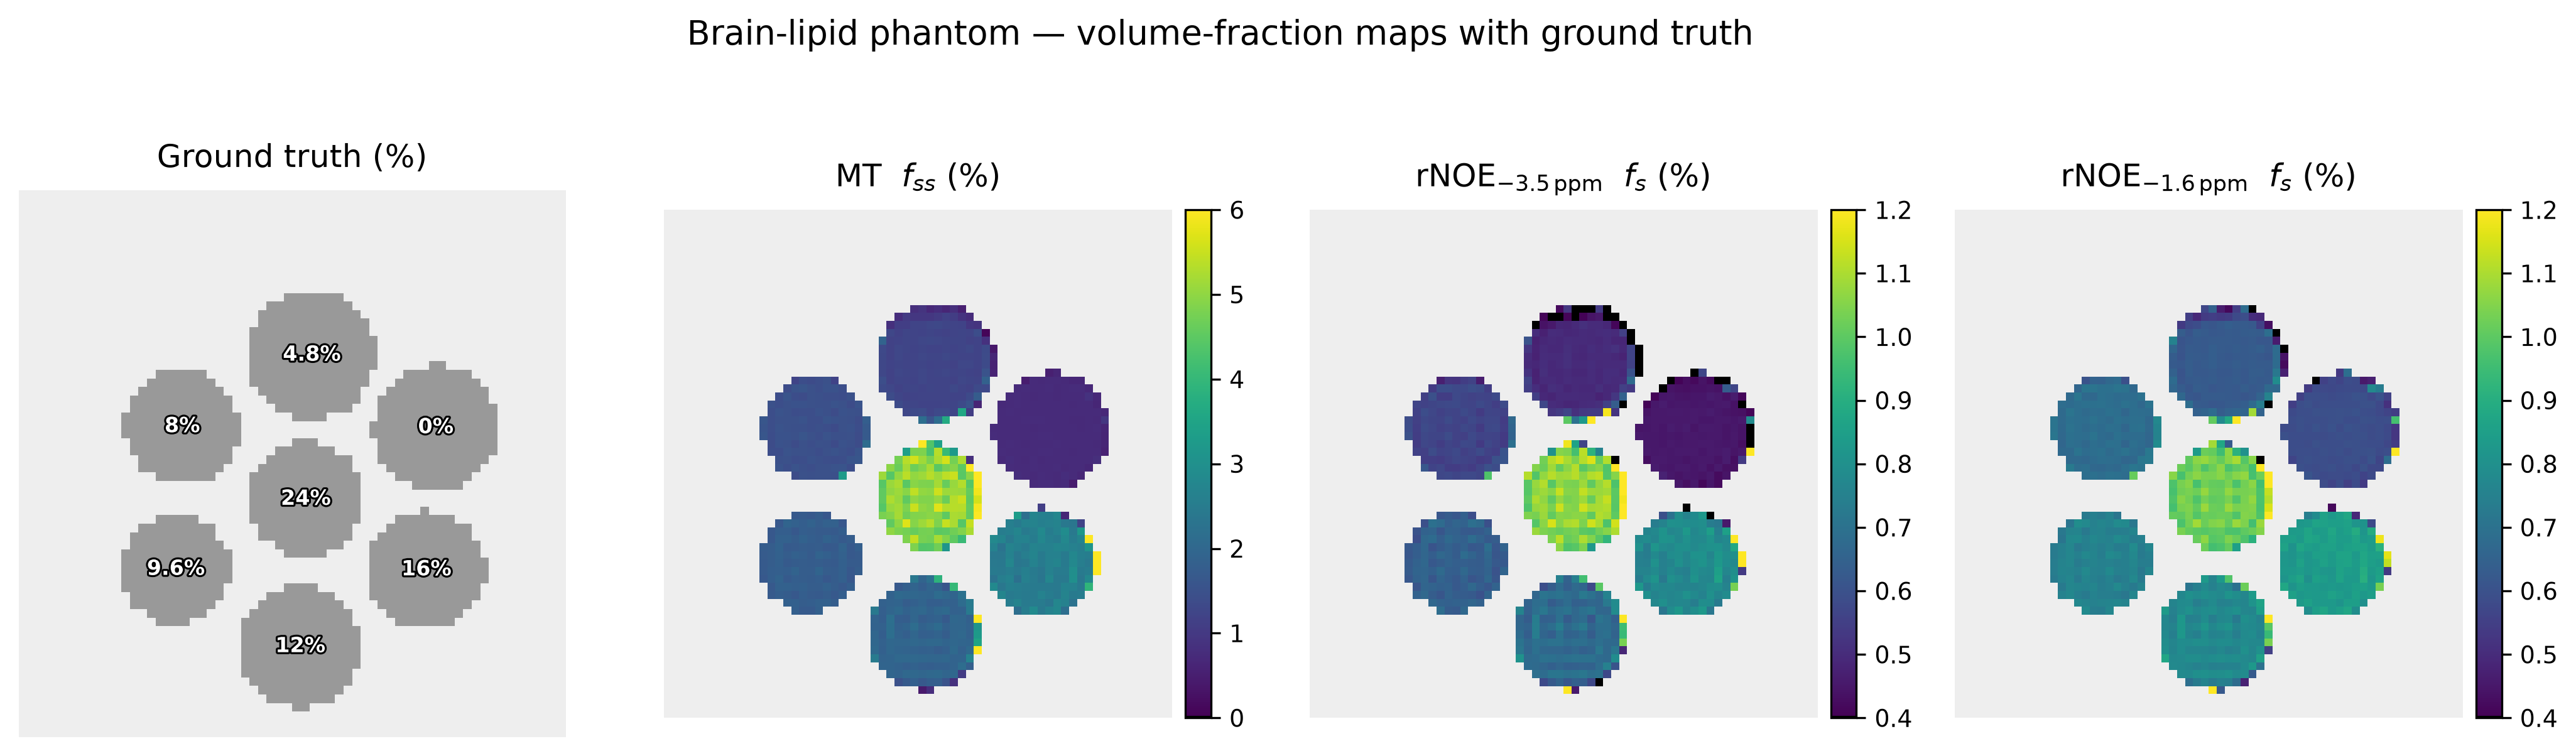

In [4]:
quantification.in_vitro_figure(mt_maps, noe_maps, tube_rois)
display(Image(filename=str(cfg.InVitro.figures / f'{cfg.InVitro.Figure.name}.png')))

## In vivo — cuprizone mice

Twelve mice at four timepoints: baseline, week 4, week 7 (peak demyelination)
and week 12 (after five weeks of recovery). 41 scans in total — group sizes
shrink after week 4.

This runs both stages over every scan and writes the maps to
`results/in_vivo/maps/`. It takes a few seconds.

In [5]:
quantification.in_vivo_quantify(device)

mouse1_week0       MT  6.56%  |  rNOE(-3.5) 1.72%  |  rNOE(-1.6) 1.30%  (0.0 s)
mouse1_week4       MT  5.99%  |  rNOE(-3.5) 1.72%  |  rNOE(-1.6) 1.30%  (0.0 s)
mouse1_week7       MT  6.06%  |  rNOE(-3.5) 1.69%  |  rNOE(-1.6) 1.27%  (0.0 s)
mouse1_week12      MT  6.74%  |  rNOE(-3.5) 1.74%  |  rNOE(-1.6) 1.29%  (0.0 s)
mouse2_week0       MT  6.92%  |  rNOE(-3.5) 1.76%  |  rNOE(-1.6) 1.33%  (0.0 s)
mouse2_week4       MT  7.14%  |  rNOE(-3.5) 1.72%  |  rNOE(-1.6) 1.32%  (0.0 s)
mouse2_week7       MT  6.80%  |  rNOE(-3.5) 1.74%  |  rNOE(-1.6) 1.33%  (0.0 s)
mouse2_week12      MT  7.52%  |  rNOE(-3.5) 1.70%  |  rNOE(-1.6) 1.31%  (0.0 s)
mouse3_week0       MT  6.89%  |  rNOE(-3.5) 1.75%  |  rNOE(-1.6) 1.30%  (0.0 s)
mouse3_week4       MT  7.57%  |  rNOE(-3.5) 1.77%  |  rNOE(-1.6) 1.35%  (0.0 s)
mouse3_week7       MT  7.79%  |  rNOE(-3.5) 1.75%  |  rNOE(-1.6) 1.31%  (0.0 s)
mouse3_week12      MT  7.52%  |  rNOE(-3.5) 1.71%  |  rNOE(-1.6) 1.31%  (0.0 s)
mouse4_week0       MT  7.12%  |  rNOE(-3

One animal across all four timepoints, showing T1, T2 and the three pool
fractions. Change `mouse` to any of `mouse1`–`mouse12`.

saved -> /run/media/paul/12cf96d7-c349-419f-bc95-4bbebbb0b6bc/momentum_de/doc/research/our_publications/journal_papers/accepted/ruth_7t_mt_noe3p5_1p6/chem_biol_imag/proof/final_code_shorten_before_public_acknowledge_claude/results/in_vivo/figures/maps_grid_mouse8_all_contrasts.pdf (+ .png)


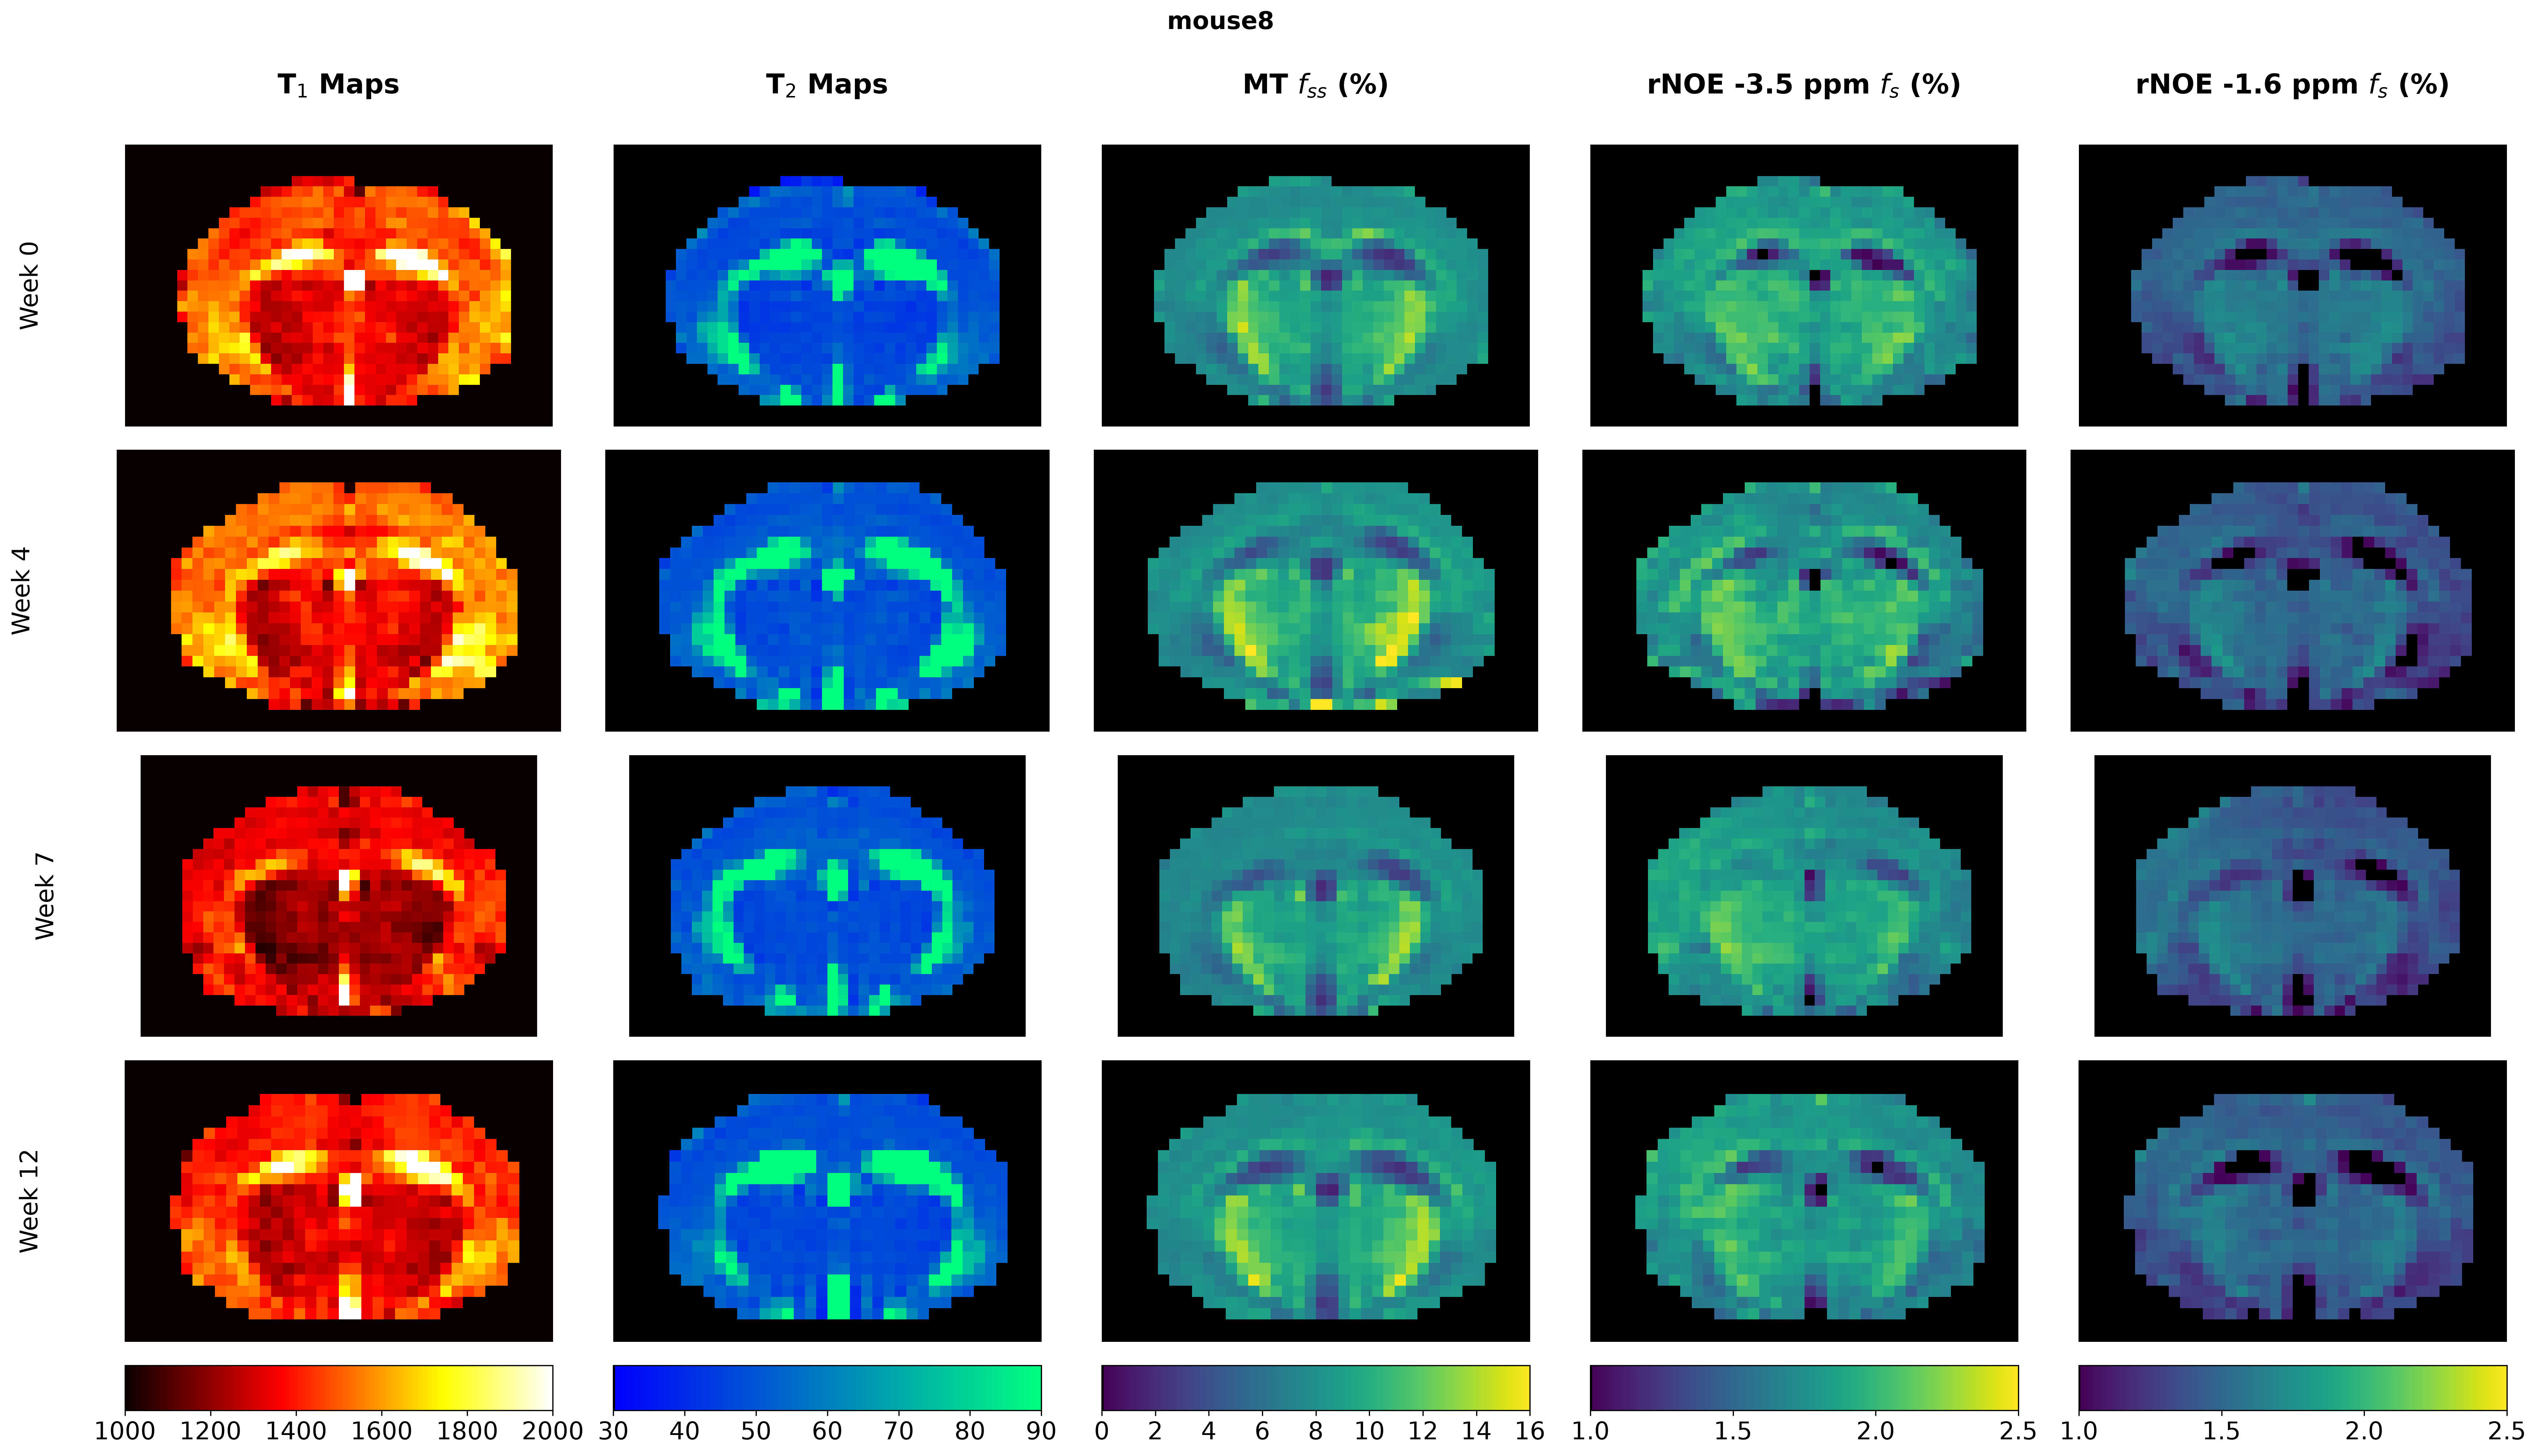

In [6]:
mouse = cfg.InVivo.Figure.representative_mouse    # 'mouse8'

quantification.in_vivo_figure(mouse)
display(Image(filename=str(cfg.InVivo.figures / f'{cfg.InVivo.Figure.name(mouse)}.png')))

## Where the results are

Everything the notebook produced is under `results/`, split by study:

```
results/in_vitro/                       results/in_vivo/
    maps/mt.mat                             maps/mt/<mouse>_week<N>_mt.mat
    maps/rnoe.mat                           maps/rnoe/<mouse>_week<N>_rnoe.mat
    figures/phantom_fs_maps_with_gt.pdf     figures/maps_grid_<mouse>_all_contrasts.pdf
                              .png                                            .png
```

**Maps** are MATLAB `.mat` files, one 64x64 array per quantity:

| file | contains |
|---|---|
| `mt.mat` | `fs` — semi-solid MT pool fraction, `ksw` — its exchange rate (s⁻¹) |
| `rnoe.mat` | `noe_minus_3p5ppm_fs`, `noe_minus_1p6ppm_fs` — the two rNOE pool fractions |

Pool fractions are stored as **fractions, not percentages** — multiply by 100 to
match the figures and the paper. The in vitro `mt.mat` additionally carries the
`t1w` and `t2w` maps (in ms) that conditioned the network, for reference.

Load one with `scipy.io.loadmat`:

```python
import scipy.io as sio
maps = sio.loadmat('results/in_vivo/maps/mt/mouse8_week0_mt.mat')
f_ss = maps['fs'] * 100        # semi-solid MT pool fraction, in %
```

**Figures** are written as both `.pdf` (for the manuscript) and `.png` (what is
shown inline above).

Re-running the notebook overwrites all of it, so nothing here needs preserving —
it regenerates in a few seconds.

In [7]:
for study in (cfg.InVitro, cfg.InVivo):
    n_maps = len(list(study.maps.rglob('*.mat')))
    print(f'{study.name}:  {n_maps} map files')
    for figure in sorted(study.figures.glob('*.pdf')):
        print(f'    {figure.relative_to(cfg.ROOT)}')

in_vitro:  2 map files
    results/in_vitro/figures/phantom_fs_maps_with_gt.pdf
in_vivo:  82 map files
    results/in_vivo/figures/maps_grid_mouse8_all_contrasts.pdf
